# Mini-Project 1: UBOS District Population Forecaster

**The question.** A district planning unit needs five-year population
forecasts so it can budget for primary-school classrooms. How many extra
classrooms will each district need by 2029?

**The data.** Population estimates in **thousands**, 2015-2024. Kampala,
Wakiso and Gulu are the figures given in the brief. They are *illustrative*,
not official UBOS releases. **Jinja** and **Mbale** are the two additional
districts required by task 1: both are long-established municipalities
outside the Kampala metropolitan belt, chosen so the comparison contains
slower-growing towns rather than five variations on the same boom.

**How the code is organised.** Nothing is computed in this notebook. The
domain classes live in `src/projects/p1_population.py`; the abstract
`Forecaster`, the error reporting and the input guards live in `src/core/`.
The notebook imports them, runs the analysis and interprets it.

In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from src.core.forecaster import Forecaster
from src.core.plotting import PALETTE, apply_style, save
from src.projects.p1_population import (
    FAMILY, LAST_TRAIN_YEAR, CAGRModel, ClassroomPlanner, DistrictPopulation,
    FibonacciRatioModel, LinearTrendModel, ModelSelector, Phase,
    bootstrap_intervals, fibonacci, forecast_frame, load_districts,
    variance_comparison)

apply_style()
SEED = 7
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", "{:,.3f}".format)

print("districts available:", ", ".join(load_districts()[i].name for i in range(5)))

districts available: Kampala, Wakiso, Gulu, Jinja, Mbale


## Task 1: the `DistrictPopulation` class

The class stores years and populations as NumPy arrays and refuses to be
built from input it cannot analyse. `__repr__` gives a one-line summary for
the console, `__len__` reports how many observations there are, and
`__contains__` answers "is this year covered?".

In [ ]:
districts = load_districts()
for d in districts:
    print(repr(d), "| len =", len(d), "| 2019 covered:", 2019 in d)

DistrictPopulation('Kampala', 2015-2024, n=10, latest=1,800k) | len = 10 | 2019 covered: True
DistrictPopulation('Wakiso', 2015-2024, n=10, latest=1,670k) | len = 10 | 2019 covered: True
DistrictPopulation('Gulu', 2015-2024, n=10, latest=480k) | len = 10 | 2019 covered: True
DistrictPopulation('Jinja', 2015-2024, n=10, latest=414k) | len = 10 | 2019 covered: True
DistrictPopulation('Mbale', 2015-2024, n=10, latest=645k) | len = 10 | 2019 covered: True


Validation is not decoration: every rejection below would otherwise become a
silently wrong forecast.

In [ ]:
bad_inputs = {
    "lengths differ": dict(years=[2020, 2021], people=[1, 2, 3]),
    "negative population": dict(years=[2020, 2021], people=[100, -5]),
    "empty series": dict(years=[], people=[]),
    "years out of order": dict(years=[2021, 2020], people=[100, 110]),
    "non-finite value": dict(years=[2020, 2021], people=[100, np.nan]),
}
for label, kwargs in bad_inputs.items():
    try:
        DistrictPopulation("Bad", **kwargs)
    except ValueError as err:
        print(f"{label:<22} -> ValueError: {err}")

lengths differ         -> ValueError: years (2) and people (3) differ in length
negative population    -> ValueError: population must be non-negative
empty series           -> ValueError: people needs at least 1 value(s), got 0
years out of order     -> ValueError: years must be strictly increasing
non-finite value       -> ValueError: people must be finite (no NaN or inf)


## Task 2: the same statistics, two ways

`statistics.variance` and `np.var` disagree because they are not estimating
the same quantity.

* `statistics.variance` is the **sample** variance. It divides the sum of
  squared deviations by `n - 1`.
* `np.var` divides by `n - ddof`, and `ddof` defaults to **0**, so out of the
  box it returns the **population** variance.

The `ddof` argument is the "delta degrees of freedom": the number subtracted
from `n` in the denominator. Setting `ddof=1` subtracts the one degree of
freedom already spent estimating the mean, which is the correction that makes
the estimator unbiased when the ten years are treated as a *sample* of a
process rather than the whole population of interest. For n = 10 the two
differ by a factor of 9/10, so the NumPy default sits 10% below the stdlib
figure.

In [ ]:
rows = []
for d in districts:
    std, npy0, npy1 = d.describe_stdlib(), d.describe_numpy(0), d.describe_numpy(1)
    rows.append({
        "district": d.name,
        "mean": std["mean"], "median": std["median"],
        "variance (statistics, n-1)": std["variance"],
        "variance (np.var, ddof=0)": npy0["variance"],
        "variance (np.var, ddof=1)": npy1["variance"],
        "stdev (statistics)": std["stdev"],
    })
stats_table = pd.DataFrame(rows).set_index("district")
stats_table

,mean,median,"variance (statistics, n-1)","variance (np.var, ddof=0)","variance (np.var, ddof=1)",stdev (statistics)
district,,,,,,
Kampala,"1,477.000","1,460.000","42,601.111","38,341.000","42,601.111",206.400
Wakiso,"1,280.000","1,260.000","60,066.667","54,060.000","60,066.667",245.085
Gulu,389.500,382.500,"2,885.833","2,597.250","2,885.833",53.720
Jinja,354.200,352.000,"1,452.400","1,307.160","1,452.400",38.110
Mbale,580.300,579.000,"1,798.011","1,618.210","1,798.011",42.403


In [ ]:
# Hand-check the relationship rather than asserting it in prose alone.
kampala = districts[0]
n = len(kampala)
sample_var = kampala.describe_stdlib()["variance"]
population_var = kampala.describe_numpy(ddof=0)["variance"]
assert np.isclose(population_var, sample_var * (n - 1) / n)
assert np.isclose(sample_var, kampala.describe_numpy(ddof=1)["variance"])
print(f"sample variance      (n-1): {sample_var:>12,.2f}")
print(f"population variance  (n)  : {population_var:>12,.2f}")
print(f"ratio                     : {population_var / sample_var:.4f}  (= 9/10)")

sample variance      (n-1):    42,601.11
population variance  (n)  :    38,341.00
ratio                     : 0.9000  (= 9/10)


## Task 3: growth rates and CAGR

Year-on-year growth answers "how fast did it grow *that* year"; the CAGR
smooths the whole decade into the single constant rate that would have taken
the district from its 2015 value to its 2024 value.

In [ ]:
growth = pd.DataFrame(
    {d.name: np.round(100 * d.yoy_growth(), 2) for d in districts},
    index=[f"{y}->{y + 1}" for y in range(2015, 2024)])
growth.loc["CAGR"] = [round(100 * d.compound_growth(), 2) for d in districts]
growth

,Kampala,Wakiso,Gulu,Jinja,Mbale
2015->2016,4.170,5.260,3.120,4.000,2.120
2016->2017,4.000,7.000,4.550,2.880,2.820
2017->2018,3.850,7.480,4.350,4.360,2.010
2018->2019,5.190,6.090,4.170,3.580,2.870
2019->2020,5.630,6.560,4.000,2.880,2.090
2020->2021,5.330,6.920,5.130,4.200,2.740
2021->2022,4.430,6.470,4.880,3.760,2.160
2022->2023,4.240,6.080,5.810,3.110,2.770
2023->2024,4.650,6.370,5.490,4.020,2.220
CAGR,4.610,6.470,4.610,3.640,2.420


In [ ]:
cagrs = {d.name: d.compound_growth() for d in districts}
fastest = max(cagrs, key=cagrs.__getitem__)
slowest = min(cagrs, key=cagrs.__getitem__)
print(f"fastest in relative terms: {fastest} at {cagrs[fastest]:.2%} a year")
print(f"slowest in relative terms: {slowest} at {cagrs[slowest]:.2%} a year")
print()
print("Note the gap between relative and absolute growth: Kampala adds the most")
print("people (600k over the decade) but Wakiso compounds faster, so Wakiso is")
print("the one whose classroom bill grows quickest.")

fastest in relative terms: Wakiso at 6.47% a year
slowest in relative terms: Mbale at 2.42% a year

Note the gap between relative and absolute growth: Kampala adds the most
people (600k over the decade) but Wakiso compounds faster, so Wakiso is
the one whose classroom bill grows quickest.


## Task 4: three forecasting models

All three subclass the abstract `Forecaster`, which declares `fit()` and
`predict(horizon)`. Two design choices are worth flagging for the viva:

1. **Validation by decorator.** `@validates_series` coerces the input, checks
   it and stores it; `@forecasts` checks the horizon and that the model has
   been fitted. Each model therefore contains only its own mathematics, and
   no guard clause is written twice.
2. **Self-registration.** A model declares `family="population"` in its class
   header and `__init_subclass__` files it into a catalogue. `ModelSelector`
   reads that catalogue, so a new model joins the comparison the moment it is
   defined -- there is no factory dictionary to forget to update.

In [ ]:
print("registered population models:", sorted(Forecaster.catalogue(FAMILY)))
demo = CAGRModel().fit(kampala.people, kampala.years.astype(float))
print(repr(demo), "| implied annual growth:", f"{demo.rate_:.2%}")
print("chained call ->", np.round(CAGRModel().fit(kampala.people).predict(3), 1))

registered population models: ['cagr', 'fibonacci-ratio', 'linear-trend']
CAGRModel(label='cagr', fitted) | implied annual growth: 4.61%
chained call -> [1882.9 1969.7 2060.5]


In [ ]:
# The Fibonacci ratios this model uses, and what they converge to.
seq = fibonacci(16)
ratios = seq[1:] / seq[:-1]
print("Fibonacci:", seq.astype(int).tolist())
print("ratios   :", np.round(ratios, 4).tolist())
print(f"\nphi = {(1 + np.sqrt(5)) / 2:.6f}  ->  implies {(np.sqrt(5) - 1) / 2:.1%} growth a year")

Fibonacci: [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610, 987]
ratios   : [1.0, 2.0, 1.5, 1.6667, 1.6, 1.625, 1.6154, 1.619, 1.6176, 1.6182, 1.618, 1.6181, 1.618, 1.618, 1.618]

phi = 1.618034  ->  implies 61.8% growth a year


## Task 5: validate before you forecast

Each model is trained on **2015-2021** and scored on the held-out
**2022-2024**. Reporting three measures guards against any one of them
flattering a model: MAE is in thousands of people, RMSE punishes large
misses, and MAPE makes districts of very different sizes comparable.

In [ ]:
selector = ModelSelector(last_train_year=LAST_TRAIN_YEAR)
print(selector)

train, test = kampala.split_at(LAST_TRAIN_YEAR)
print(f"\ntrain: {train.years[0]}-{train.years[-1]} (n={len(train)})")
print(f"test : {test.years[0]}-{test.years[-1]} (n={len(test)})")
print("2021 is in the", kampala.phase_of(2021), "set; 2022 is in the",
      kampala.phase_of(2022), "set")

ModelSelector(split=2021, models=['cagr', 'fibonacci-ratio', 'linear-trend'])

train: 2015-2021 (n=7)
test : 2022-2024 (n=3)
2021 is in the train set; 2022 is in the test set


In [ ]:
for d in districts:
    print(f"\n=== {d.name} " + "=" * (48 - len(d.name)))
    print(selector.table(d).to_string())
    label, report = selector.best(d)
    print(f"--> selected: {label}")


=== Kampala =========================================
                      MAE      RMSE  MAPE_%
model                                      
cagr                9.619    10.385   0.551
linear-trend       37.619    38.975   2.165
fibonacci-ratio 2,738.539 3,193.752 155.748
--> selected: cagr

=== Wakiso ==========================================
                      MAE      RMSE  MAPE_%
model                                      
cagr                6.802     8.049   0.420
linear-trend       49.405    52.368   3.094
fibonacci-ratio 2,351.985 2,748.539 145.438
--> selected: cagr

=== Gulu ============================================
                    MAE    RMSE  MAPE_%
model                                  
cagr              9.437  10.869   2.025
linear-trend     18.571  20.287   4.009
fibonacci-ratio 702.828 819.806 150.666
--> selected: cagr

=== Jinja ===========================================
                    MAE    RMSE  MAPE_%
model                                  
cag

In [ ]:
summary = pd.DataFrame(
    [{"district": d.name, **{r.model: r.mape for r in selector.reports(d)},
      "selected": selector.best(d)[0]} for d in districts]).set_index("district")
summary.columns = [c if c == "selected" else f"MAPE% {c}" for c in summary.columns]
summary

,MAPE% cagr,MAPE% fibonacci-ratio,MAPE% linear-trend,selected
district,,,,
Kampala,0.551,155.748,2.165,cagr
Wakiso,0.420,145.438,3.094,cagr
Gulu,2.025,150.666,4.009,cagr
Jinja,0.194,160.416,1.288,cagr
Mbale,0.164,167.474,0.550,cagr


**Result.** The CAGR model wins on all five districts, with MAPE between
0.16% and 2.03%. The linear trend is consistently second: it is not absurd,
but a straight line cannot bend, so it falls progressively further behind a
series that compounds. The Fibonacci-ratio model is wrong by 145-167%.

## Task 6: forecast 2025-2029, and compare variances

The selected model is refitted on the **full** 2015-2024 series before
forecasting, so the final forecast uses every observation available.

In [ ]:
forecasts = {}
for d in districts:
    model = selector.fit_best(d)
    forecasts[d.name] = {"model": model, "path": model.predict(5)}

forecast_table = pd.DataFrame({name: np.round(f["path"], 1)
                               for name, f in forecasts.items()},
                              index=range(2025, 2030))
forecast_table.index.name = "year"
forecast_table

,Kampala,Wakiso,Gulu,Jinja,Mbale
year,,,,,
2025,"1,882.900","1,778.000",502.100,429.100,660.600
2026,"1,969.700","1,893.000",525.300,444.700,676.600
2027,"2,060.500","2,015.500",549.500,460.900,693.000
2028,"2,155.400","2,145.900",574.800,477.700,709.800
2029,"2,254.800","2,284.700",601.300,495.100,727.000


In [ ]:
variance_rows = []
for d in districts:
    result = variance_comparison(d, forecasts[d.name]["path"])
    variance_rows.append({"district": d.name, **result})
pd.DataFrame(variance_rows).set_index("district")

,actual_variance,forecast_variance,ratio
district,,,
Kampala,"42,601.111","21,607.682",0.507
Wakiso,"60,066.667","40,131.362",0.668
Gulu,"2,885.833","1,536.546",0.532
Jinja,"1,452.400",681.507,0.469
Mbale,"1,798.011",688.482,0.383


**What the variance difference tells you.** The forecast series is less
variable than the observed one in every district (ratios of 0.38-0.67). That
is not evidence that the future will be calmer. It is a property of the
estimator: the observed series carries both the trend *and* a decade of
year-to-year scatter, whereas a fitted CAGR curve is a smooth deterministic
path with the scatter removed. Reporting the forecast variance as though it
were a measure of uncertainty would therefore understate the risk badly.
Genuine forecast uncertainty has to be reconstructed separately, which is
what the bootstrap extension below does.

## Task 7: actual, fitted and forecast

saved: mp1_forecasts.png


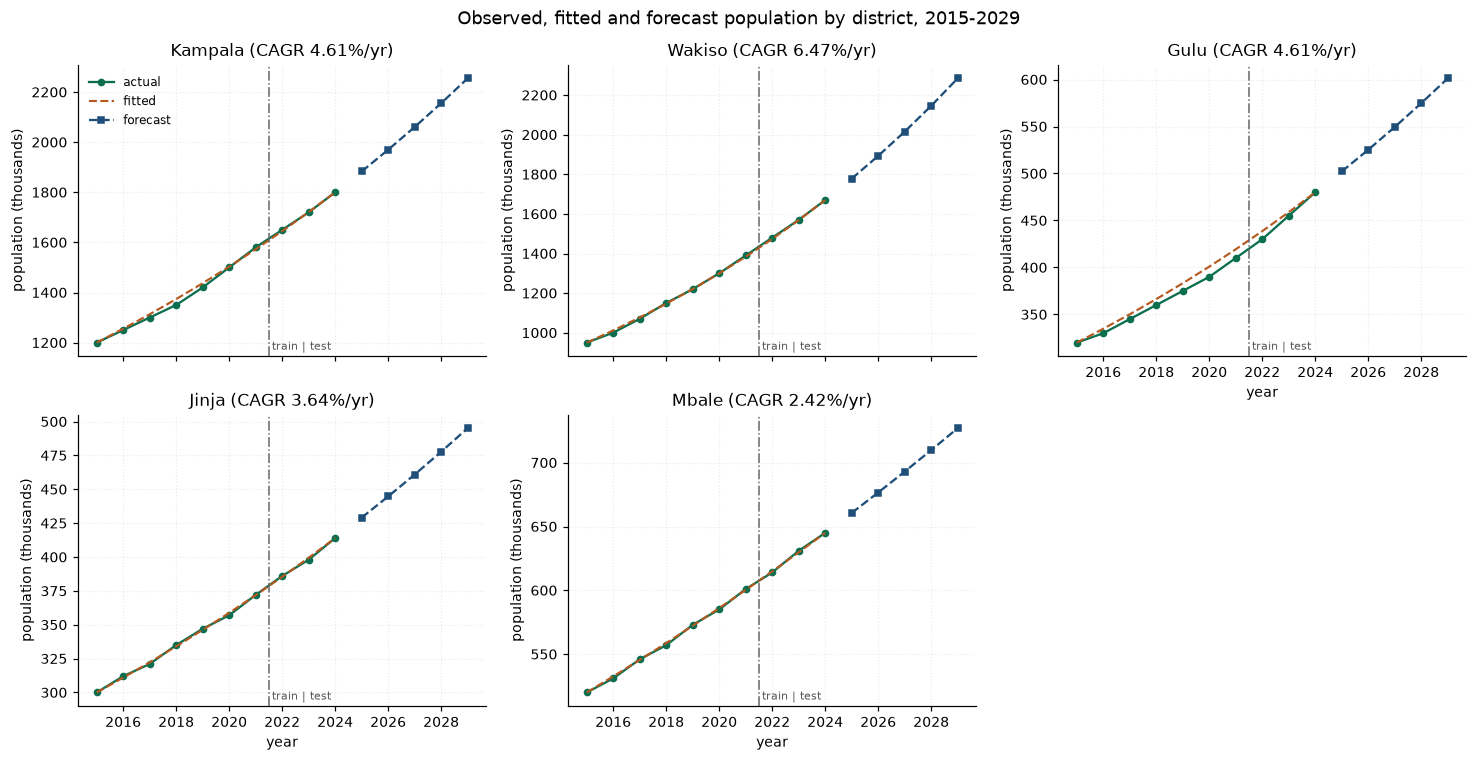

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7), sharex=True)
for ax, d in zip(axes.flat, districts):
    model = forecasts[d.name]["model"]
    path = forecasts[d.name]["path"]
    future = np.arange(2025, 2030)

    ax.plot(d.years, d.people, "o-", color=PALETTE[0], label="actual", ms=4)
    ax.plot(d.years, model.fitted(), "--", color=PALETTE[1], lw=1.4, label="fitted")
    ax.plot(future, path, "s--", color=PALETTE[2], ms=4, label="forecast")
    ax.axvline(LAST_TRAIN_YEAR + 0.5, color="0.4", lw=1, ls="-.")
    ax.annotate("train | test", xy=(LAST_TRAIN_YEAR + 0.5, ax.get_ylim()[0]),
                xytext=(2, 4), textcoords="offset points", fontsize=7, color="0.35")
    ax.set_title(f"{d.name} (CAGR {d.compound_growth():.2%}/yr)")
    ax.set_ylabel("population (thousands)")

axes.flat[-1].axis("off")
axes.flat[0].legend(loc="upper left", fontsize=8)
# The bottom-right cell is empty, so Gulu above it needs its own x labels back.
axes[0, 2].tick_params(labelbottom=True)
for ax in (axes[0, 2], *axes[1, :2]):
    ax.set_xlabel("year")
fig.suptitle("Observed, fitted and forecast population by district, 2015-2029",
             fontsize=12)
fig.tight_layout()
print("saved:", save(fig, "mp1_forecasts.png").name)
plt.show()

## Task 8: how many extra classrooms by 2029?

The brief's planning assumptions: 18% of the population is of primary-school
age and one classroom holds 53 pupils. `ClassroomPlanner` is a frozen
dataclass, so a planning scenario cannot be edited halfway through an
analysis -- a different assumption means a new, clearly-named object.

In [ ]:
planner = ClassroomPlanner()
print(planner)

plan_rows = []
for d in districts:
    pop_2029 = float(forecasts[d.name]["path"][-1])
    plan_rows.append({
        "district": d.name,
        "2024 (k)": d.people[-1],
        "2029 (k)": round(pop_2029, 1),
        "growth (k)": round(pop_2029 - d.people[-1], 1),
        "new pupils": round(planner.pupils(pop_2029 - d.people[-1])),
        "extra classrooms": planner.additional(d.people[-1], pop_2029),
    })
plan = pd.DataFrame(plan_rows).set_index("district")
plan

ClassroomPlanner(age_share=0.18, class_size=53)


,2024 (k),2029 (k),growth (k),new pupils,extra classrooms
district,,,,,
Kampala,"1,800.000","2,254.800",454.800,81857,1545
Wakiso,"1,670.000","2,284.700",614.700,110641,2088
Gulu,480.000,601.300,121.300,21829,412
Jinja,414.000,495.100,81.100,14602,276
Mbale,645.000,727.000,82.000,14760,279


In [ ]:
# Hand-check Kampala end to end, independently of the classes.
rate = kampala.compound_growth()
hand_2029 = kampala.people[-1] * (1 + rate) ** 5
hand_rooms = int(np.ceil((hand_2029 - kampala.people[-1]) * 1_000 * 0.18 / 53))
assert hand_rooms == plan.loc["Kampala", "extra classrooms"]
print(f"hand calculation: 1800 x 1.04608^5 = {hand_2029:,.1f}k")
print(f"                  ({hand_2029:,.1f} - 1800) x 1000 x 0.18 / 53 = {hand_rooms:,} rooms")
print(f"class output    : {plan.loc['Kampala', 'extra classrooms']:,} rooms  [match]")
print(f"\ntotal across five districts: {plan['extra classrooms'].sum():,} classrooms")

hand calculation: 1800 x 1.04608^5 = 2,254.8k
                  (2,254.8 - 1800) x 1000 x 0.18 / 53 = 1,545 rooms
class output    : 1,545 rooms  [match]

total across five districts: 4,600 classrooms


## Extension 1: bootstrap prediction intervals

The point forecast has no uncertainty attached to it. The residual bootstrap
supplies some: draw the model's own training residuals with replacement
(2,000 resamples here, above the 1,000 the brief asks for), add them to the
forecast path, and read the 2.5th and 97.5th percentiles off the result.

In [ ]:
intervals = {d.name: bootstrap_intervals(forecasts[d.name]["model"], horizon=5,
                                         n_boot=2000, level=0.95, seed=SEED)
             for d in districts}

band = pd.DataFrame([{
    "district": name,
    "2029 point": round(float(ci["point"][-1]), 1),
    "2029 lower": round(float(ci["lower"][-1]), 1),
    "2029 upper": round(float(ci["upper"][-1]), 1),
    "rooms (point)": planner.additional(dict(zip([d.name for d in districts],
                                                 [d.people[-1] for d in districts]))[name],
                                        float(ci["point"][-1])),
    "rooms (upper)": planner.additional(dict(zip([d.name for d in districts],
                                                 [d.people[-1] for d in districts]))[name],
                                        float(ci["upper"][-1])),
} for name, ci in intervals.items()]).set_index("district")
band

,2029 point,2029 lower,2029 upper,rooms (point),rooms (upper)
district,,,,,
Kampala,"2,254.800","2,231.100","2,262.300",1545,1571
Wakiso,"2,284.700","2,273.200","2,291.400",2088,2111
Gulu,601.300,590.400,601.300,412,412
Jinja,495.100,493.300,496.200,276,280
Mbale,727.000,725.300,728.300,279,283


saved: mp1_intervals.png


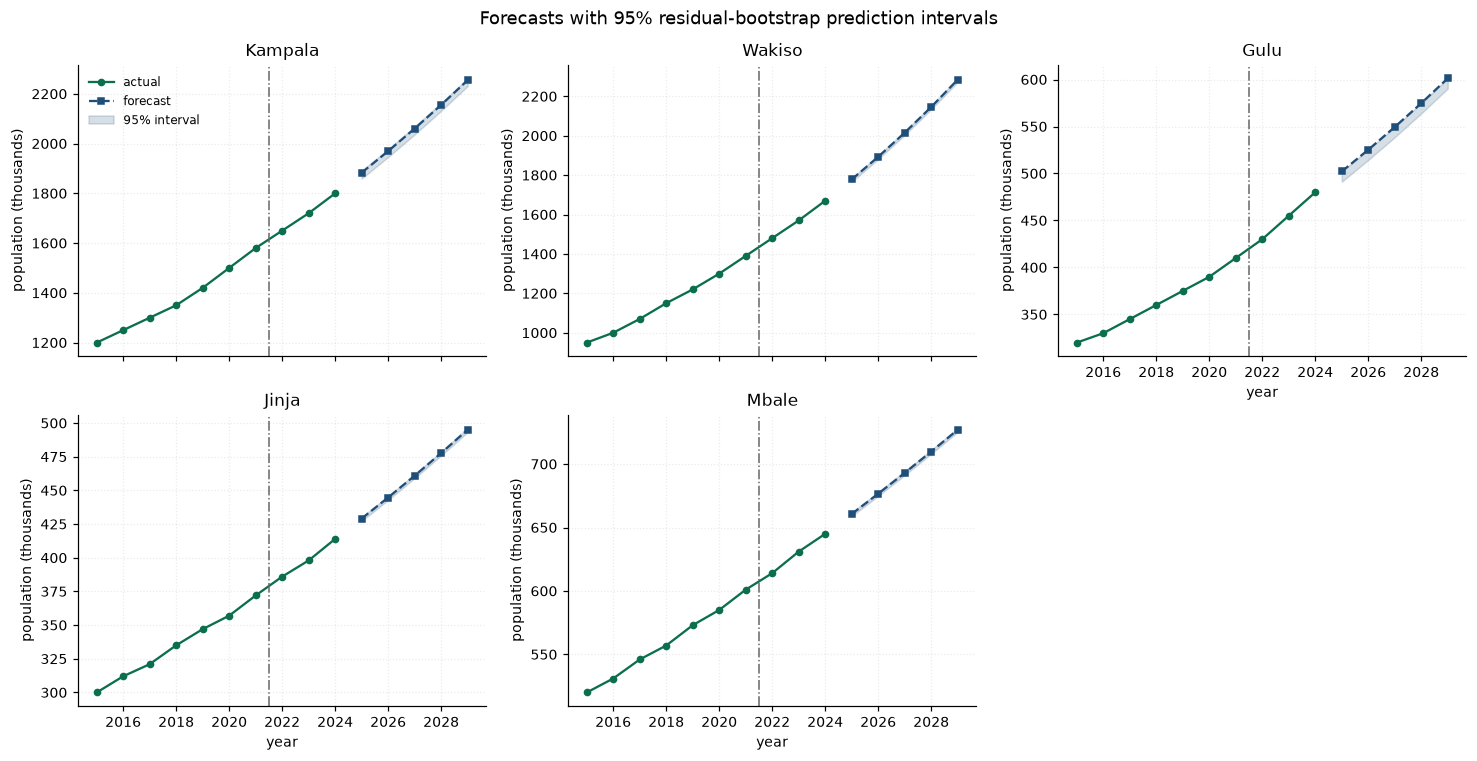

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7), sharex=True)
future = np.arange(2025, 2030)
for ax, d in zip(axes.flat, districts):
    ci = intervals[d.name]
    ax.plot(d.years, d.people, "o-", color=PALETTE[0], ms=4, label="actual")
    ax.plot(future, ci["point"], "s--", color=PALETTE[2], ms=4, label="forecast")
    ax.fill_between(future, ci["lower"], ci["upper"], color=PALETTE[2], alpha=0.18,
                    label="95% interval")
    ax.axvline(LAST_TRAIN_YEAR + 0.5, color="0.4", lw=1, ls="-.")
    ax.set_title(d.name)
    ax.set_ylabel("population (thousands)")

axes.flat[-1].axis("off")
axes.flat[0].legend(loc="upper left", fontsize=8)
axes[0, 2].tick_params(labelbottom=True)
for ax in (axes[0, 2], *axes[1, :2]):
    ax.set_xlabel("year")
fig.suptitle("Forecasts with 95% residual-bootstrap prediction intervals", fontsize=12)
fig.tight_layout()
print("saved:", save(fig, "mp1_intervals.png").name)
plt.show()

The bands are narrow -- the upper bound adds only about 1% to the classroom
bill. That is a finding about the *method*, not reassurance about the future.
A CAGR curve is anchored on the first and last observations, so it passes
exactly through both and its training residuals are small by construction.
Resampling those residuals therefore measures how well the curve fits points
it was pinned to, not how wrong the constant-growth assumption might be by
2029. The honest reading is that these intervals capture fit error and say
nothing about model error, which is the larger risk here.

## Extension 2: is the Fibonacci-ratio model ever defensible?

Successive Fibonacci ratios converge on the golden ratio
phi = 1.6180..., so after a handful of terms the model is simply multiplying
by 1.618 every year. That is a standing assumption of **61.8% annual
population growth**.

In [ ]:
fib_rows = []
for d in districts:
    reports = {r.model: r for r in selector.reports(d)}
    fib_rows.append({"district": d.name,
                     "MAPE% fibonacci": reports["fibonacci-ratio"].mape,
                     "MAPE% cagr": reports["cagr"].mape,
                     "actual CAGR %": 100 * d.compound_growth()})
pd.DataFrame(fib_rows).set_index("district")

,MAPE% fibonacci,MAPE% cagr,actual CAGR %
district,,,
Kampala,155.748,0.551,4.608
Wakiso,145.438,0.420,6.469
Gulu,150.666,2.025,4.608
Jinja,160.416,0.194,3.644
Mbale,167.474,0.164,2.422


In [ ]:
implied = (1 + np.sqrt(5)) / 2 - 1
print(f"growth implied by the golden ratio : {implied:.1%} a year")
print(f"fastest district actually observed : {max(cagrs.values()):.1%} a year (Wakiso)")
print(f"overstatement                      : {implied / max(cagrs.values()):.0f}x")
print()
print("Doubling time at 61.8% a year:", round(np.log(2) / np.log(1 + implied), 1), "years")
print("Doubling time at Wakiso's 6.5%:", round(np.log(2) / np.log(1.0647), 1), "years")

growth implied by the golden ratio : 61.8% a year
fastest district actually observed : 6.5% a year (Wakiso)
overstatement                      : 10x

Doubling time at 61.8% a year: 1.4 years
Doubling time at Wakiso's 6.5%: 11.1 years


**Assessment.** The model is defensible only where the quantity genuinely
grows at about 61.8% per period, and where each new value really is the sum
of the previous two. Neither holds for a district population: people are not
produced by adding the last two years together, and no Ugandan district has
ever sustained 61.8% annual growth. It is defensible in the narrow sense that
it is reproducible and cheap, and it would be a reasonable *lower* bound on
an early-stage epidemic or a viral adoption curve for a few periods before
saturation bites. As a population model it fails on three counts: the growth
rate is not estimated from the data at all, it is unbounded, and it ignores
the carrying capacity that land, water and services impose. Keeping it in the
comparison is still worthwhile -- it is the control that shows the validation
step is doing real work.

## Findings & Limitations

**Findings.** Every district in the sample grows close to exponentially, so
the CAGR model wins the 2022-2024 validation outright, with MAPE between
0.16% (Mbale) and 2.03% (Gulu). The linear trend is a respectable second
(0.55-4.01%) but drifts low because it cannot curve; the Fibonacci-ratio
model misses by 145-167% because its ratios converge on the golden ratio and
so assume 61.8% annual growth, roughly ten times the fastest rate actually
observed. Wakiso compounds fastest at 6.47% a year and Mbale slowest at
2.42%. Projected to 2029, the five districts need about **4,600 additional
primary classrooms** between them: Wakiso 2,088, Kampala 1,545, Gulu 412,
Mbale 279 and Jinja 276. Wakiso overtaking Kampala is the result that matters
for budgeting, and it is driven by relative growth, not size. The 95%
bootstrap upper bound adds only about 1% to that total.

**Limitations.** The data are illustrative, so the magnitudes are
indicative only. A CAGR fitted to two endpoints ignores everything in
between and assumes the next five years resemble the last nine, which rules
out boundary changes, migration shocks and the fertility decline already
visible in UBOS projections. The bootstrap intervals capture fit error only:
because the CAGR curve is pinned to the first and last observations, its
residuals understate how wrong the constant-growth assumption itself could
be. The 18% primary-age share and 53-pupil classroom are national averages
applied uniformly, yet both plausibly differ between Kampala and Gulu, and
the planning figure counts rooms for *additional* pupils only -- it says
nothing about the backlog already there in 2024.